In [ ]:
#imports
from collections import Counter
from math import log
from math import exp
import matplotlib.pyplot as plt

#source code
def read_documents(doc_file):
    docs = []
    labels = []
    with open(doc_file, encoding='utf-8') as f:
        for line in f:
            words = line.strip().split()
            docs.append(words[3:])
            labels.append(words[1])
    return docs, labels

In [ ]:
all_docs, all_labels = read_documents('all_sentiment_shuffled.txt')#download own data
split_point = int(0.80 * len(all_docs)) #split data
train_docs = all_docs[:split_point]
train_labels = all_labels[:split_point]
eval_docs = all_docs[split_point:]
eval_labels = all_labels[split_point:]

def train_nb(documents, labels):
    class_counts = Counter(labels)
    word_counts = {}
    total_words = Counter()
    vocabulary = set()

    for document, label in zip(documents, labels):
        if label not in word_counts:
            word_counts[label] = Counter()
        word_counts[label].update(document)
        total_words[label] += len(document)
        vocabulary.update(document)

    return class_counts, word_counts, total_words, vocabulary

def score_doc_label(document, label, model):
    class_counts, word_counts, total_words, vocabulary = model
    score = log(class_counts[label] / sum(class_counts.values()))
    denominator = total_words[label] + len(vocabulary) + 1

    for word in document:
        score += log((word_counts[label][word] + 1) / denominator)

    return score

def classify_nb(document, model):
    labels = model[0].keys()
    scores = {}
    for label in labels:
        scores[label] = score_doc_label(document, label, model)
    return max(scores, key=scores.get)

def classify_documents(docs, model):
    guesses = []
    for document in docs:
        guesses.append(classify_nb(document, model))
    return guesses

def accuracy(true_labels, guessed_labels):
    correct = 0
    for true_label, guessed_label in zip(true_labels, guessed_labels):
        if true_label == guessed_label:
            correct += 1
    return correct / len(true_labels)


test accuracy: 0.8153587914393622
test F1: 0.8046181172291297


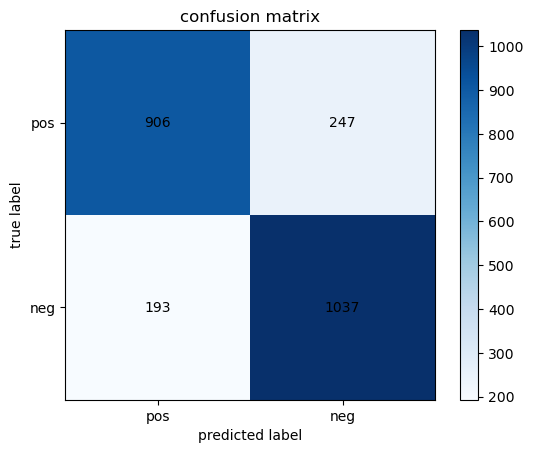

In [ ]:
#eval:
model = train_nb(train_docs, train_labels)
eval_guesses = classify_documents(eval_docs, model)
print('test accuracy:', accuracy(eval_labels, eval_guesses))

#measure accuracy and F1 score plus show the confusion matrix
true_pos = 0
false_pos = 0
false_neg = 0
for true_label, guessed_label in zip(eval_labels, eval_guesses):
    if true_label == 'pos' and guessed_label == 'pos':
        true_pos += 1
    elif true_label == 'neg' and guessed_label == 'pos':
        false_pos += 1
    elif true_label == 'pos' and guessed_label == 'neg':
        false_neg += 1

f1_denominator = 2 * true_pos + false_pos + false_neg
f1 = 2 * true_pos / f1_denominator if f1_denominator > 0 else 0
print('test F1:', f1)

confusion_matrix = [[0, 0], [0, 0]]
for true_label, guessed_label in zip(eval_labels, eval_guesses):
    true_index = 0 if true_label == 'pos' else 1
    guessed_index = 0 if guessed_label == 'pos' else 1
    confusion_matrix[true_index][guessed_index] += 1

plt.imshow(confusion_matrix, cmap='Blues')
plt.xticks([0, 1], ['pos', 'neg'])
plt.yticks([0, 1], ['pos', 'neg'])
plt.xlabel('predicted label')
plt.ylabel('true label')
plt.title('confusion matrix')

for i in range(2):
    for j in range(2):
        plt.text(j, i, confusion_matrix[i][j], ha='center', va='center')

plt.colorbar()
plt.show()


Our overall Accuracy, F1 and Confusion matrix look quite good. We have reasonbaly high accuracy of above 80% in all cases. Our prediction skew is low as we roughly misclassify postivies equally likely to negatives which is great for generalizability.

In [27]:
confident_mistakes = []
for i, (document, true_label, guessed_label) in enumerate(zip(eval_docs, eval_labels, eval_guesses)):
    if true_label != guessed_label:
        scores = {}
        for label in model[0]:
            scores[label] = score_doc_label(document, label, model)
        max_score = max(scores.values())
        denominator = sum(exp(score - max_score) for score in scores.values())
        confidence = exp(scores[guessed_label] - max_score) / denominator
        if confidence >= 0.9:
            confident_mistakes.append((confidence, i, document, true_label, guessed_label))

confident_mistakes.sort(reverse=True)
if len(confident_mistakes) == 0:
    print('no high-confidence mistakes found')
for confidence, i, document, true_label, guessed_label in confident_mistakes[:5]:
    print('true:', true_label, 'predicted:', guessed_label)
    print('predicted probability:', round(confidence, 3))
    print('review:', ' '.join(document))
    print()

true: neg predicted: pos
predicted probability: 1.0
review: we bought this camera thinking that it would be our do-all " eurocam " for an upcoming trip to europe . it promised a sufficient range of performance and features to easily meet our needs on such a trip . sadly , the camera is not up to filling this role . we will need to take another camera along with it . however , we will take the v705 for its wide-angle lens , the reason that we picked this model in the first place . it is this disparity between the advertised and actual capabilities of the camera which prompts me to contribute this review . the need for a true wide-angle lens is both a sufficient and a necessary condition for buying this camera . if you do not need a 23mm lens , or if you do not know if you need a 23mm lens , then you do not need this otherwise mediocre p&s ( point and shoot ) camera . good : fairly decent 23mm wide-angle lens ; the 23mm is the default lens ; rapid start-up time ; internal focus and zoom 

Looking at some of the cases of misclassification such as the second review seen above, it talks about norton and uses a lot of words such as: like, wins, etc that would be common positive words but uses more obscure or likely unseen negative phrases like: hit and miss or memory hog. These combinations are likely much more rare so they would have lower probbailities to skew the classifier while seeing like would be a very common way to express positive thoughts. This is a similar case for all the other classifiers as well.